In [2]:
## 1. Import Libraries
!pip install -q torchsummary kagglehub
from torchvision import datasets
import torchvision.transforms as transforms

from torch.utils.data import Dataset, DataLoader, random_split
import torch
import torch.nn as nn
from torch.optim import Adam

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


LOAD AND EXPLORE DATASET
- Link: https://www.kaggle.com/datasets/emmarex/plantdisease
- About 20,600 colour leaf images, original size 256 x 256
- 15 classes from 3 plants: Pepper bell (2 classes), Potato (3 classes), Tomato (10 classes)
- The dataset has one folder for each class. It has no ready train/test folders, so it is splited it in the next section.


In [4]:
import os
import kagglehub

# Download the dataset from Kaggle
path = kagglehub.dataset_download("emmarex/plantdisease")
print("Path to dataset files:", path)

# Find the folder that has all the class folders inside
data_folder = None
for root, dirs, files in os.walk(path):
    if "Tomato_healthy" in dirs:
        data_folder = root
        break
print("Data folder:", data_folder)

Using Colab cache for faster access to the 'plantdisease' dataset.
Path to dataset files: /kaggle/input/plantdisease
Data folder: /kaggle/input/plantdisease/PlantVillage


In [5]:
# Load all images. Every class folder becomes one class.
full_data = datasets.ImageFolder(data_folder)

print("Total images:", len(full_data))
print("Number of classes:", len(full_data.classes))
print()

# Show how many images each class has
counts = np.bincount(full_data.targets)
for name, c in zip(full_data.classes, counts):
    print(f"{name:50s} {c}")

Total images: 20638
Number of classes: 15

Pepper__bell___Bacterial_spot                      997
Pepper__bell___healthy                             1478
Potato___Early_blight                              1000
Potato___Late_blight                               1000
Potato___healthy                                   152
Tomato_Bacterial_spot                              2127
Tomato_Early_blight                                1000
Tomato_Late_blight                                 1909
Tomato_Leaf_Mold                                   952
Tomato_Septoria_leaf_spot                          1771
Tomato_Spider_mites_Two_spotted_spider_mite        1676
Tomato__Target_Spot                                1404
Tomato__Tomato_YellowLeaf__Curl_Virus              3208
Tomato__Tomato_mosaic_virus                        373
Tomato_healthy                                     1591


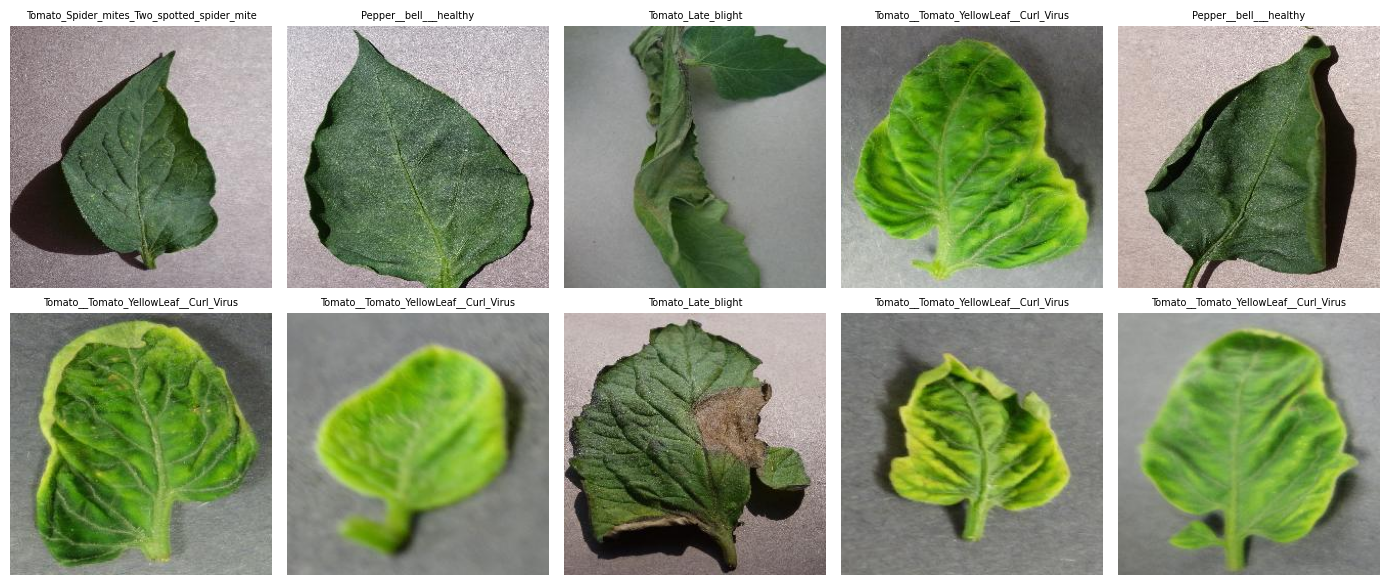

In [6]:
# Show some random images with their class names
ROWS, COLS = 2, 5
fig, axes = plt.subplots(ROWS, COLS, figsize=(14, 6))
for ax in axes.flat:
    i = np.random.randint(len(full_data))
    img, label = full_data[i]
    ax.imshow(img)
    ax.set_title(full_data.classes[label], fontsize=7)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Data Preprocessing and Augmentation

- Resize to 64 x 64: Small images train faster, and the CNN needs all images to be the same size.
- ToTensor: Changes the image to numbers between 0 and 1.
- Augmentation (train data only): Random flip, small rotation and small colour change. This makes new versions of the same picture, so the model does not just remember the training pictures.
- Validation and test data: No augmentation, so the score is fair.
- Split:70% train, 20% validation, 10% test (random split).

In [7]:
size = 64

train_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

# Same folder loaded two times: one with augmentation, one without
aug_data = datasets.ImageFolder(data_folder, transform=train_transform)
plain_data = datasets.ImageFolder(data_folder, transform=val_transform)

# Split sizes: 70% train, 20% validation, 10% test
total = len(aug_data)
train_size = int(0.7 * total)
val_size = int(0.2 * total)
test_size = total - train_size - val_size

# Same seed gives the same split for both copies, so no image is in two sets
train_data, _, _ = random_split(aug_data, [train_size, val_size, test_size],
                                generator=torch.Generator().manual_seed(42))
_, val_data, test_data = random_split(plain_data, [train_size, val_size, test_size],
                                      generator=torch.Generator().manual_seed(42))

In [8]:
print('Dataset Summary')
print('Train Data: ', len(train_data))
print('Validation Data: ', len(val_data))
print('Test Data: ', len(test_data))
print('Classes and Indices: ', aug_data.class_to_idx)

Dataset Summary
Train Data:  14446
Validation Data:  4127
Test Data:  2065
Classes and Indices:  {'Pepper__bell___Bacterial_spot': 0, 'Pepper__bell___healthy': 1, 'Potato___Early_blight': 2, 'Potato___Late_blight': 3, 'Potato___healthy': 4, 'Tomato_Bacterial_spot': 5, 'Tomato_Early_blight': 6, 'Tomato_Late_blight': 7, 'Tomato_Leaf_Mold': 8, 'Tomato_Septoria_leaf_spot': 9, 'Tomato_Spider_mites_Two_spotted_spider_mite': 10, 'Tomato__Target_Spot': 11, 'Tomato__Tomato_YellowLeaf__Curl_Virus': 12, 'Tomato__Tomato_mosaic_virus': 13, 'Tomato_healthy': 14}


In [10]:
# Hyperparameters
batch_size = 32
learning_rate = 1e-3
epoch_number = 20

In [11]:
trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

## 4. Define CNN Architecture

**Feature extraction (finds patterns):**
Conv2d(3, 64) then Conv2d(64, 64)then MaxPool
Conv2d(64, 128) then Conv2d(128, 128) then MaxPool
- The second conv in each block keeps the same number of channels (64 to 64, 128 to 128) so it can improve the patterns found by the first one.
- ReLU after each conv layer lets the network learn non-straight-line patterns. MaxPool makes the image smaller.

In [12]:
def get_model(choice):
    if choice == "A":
        model = nn.Sequential(
            # Feature Extraction
            nn.Conv2d(3, 64, kernel_size=3),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Classifier
            nn.Flatten(),
            nn.Linear(128*13*13, 256),
            nn.ReLU(),
            nn.Linear(256, 15)
        ).to(device)

    elif choice == "B":
        model = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(128*13*13, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 15)
        ).to(device)

    else:
        model = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(128*13*13, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 15)
        ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

In [13]:
# Detailed summary of the architecture (Model A)
from torchsummary import summary
model, loss_fn, optimizer = get_model("A")
summary(model, input_size=(3, size, size));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 62, 62]           1,792
              ReLU-2           [-1, 64, 62, 62]               0
            Conv2d-3           [-1, 64, 60, 60]          36,928
              ReLU-4           [-1, 64, 60, 60]               0
         MaxPool2d-5           [-1, 64, 30, 30]               0
            Conv2d-6          [-1, 128, 28, 28]          73,856
              ReLU-7          [-1, 128, 28, 28]               0
            Conv2d-8          [-1, 128, 26, 26]         147,584
              ReLU-9          [-1, 128, 26, 26]               0
        MaxPool2d-10          [-1, 128, 13, 13]               0
          Flatten-11                [-1, 21632]               0
           Linear-12                  [-1, 256]       5,538,048
             ReLU-13                  [-1, 256]               0
           Linear-14                   

In [14]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)

@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

In [15]:
## Training Loop: train Model A, B and C one by one ##
all_models = {}
all_history = {}

for choice in ["A", "B", "C"]:
    print("=" * 60)
    print("Training Model", choice)
    print("=" * 60)

    torch.manual_seed(42)
    model, loss_fn, optimizer = get_model(choice)

    train_losses, train_accuracies = [], []
    val_losses, val_accuracies = [], []

    for epoch in range(epoch_number):
        epoch_loss, epoch_accuracy = train_one_epoch(trn_dl, model, loss_fn, optimizer)
        train_losses.append(epoch_loss)
        train_accuracies.append(epoch_accuracy)

        v_loss, v_acc = validation(val_dl, model, loss_fn)
        val_losses.append(v_loss)
        val_accuracies.append(v_acc)

        print(f"Epoch [{epoch + 1}/{epoch_number}]"
              f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
              f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

    all_models[choice] = model
    all_history[choice] = (train_losses, train_accuracies, val_losses, val_accuracies)

Training Model A
Epoch [1/20] | Train Loss: 1.6001 | Train Accuracy: 47.58% | Val Loss: 0.9580 | Val Accuracy: 67.41%
Epoch [2/20] | Train Loss: 0.8839 | Train Accuracy: 70.24% | Val Loss: 0.6787 | Val Accuracy: 78.07%
Epoch [3/20] | Train Loss: 0.6286 | Train Accuracy: 78.74% | Val Loss: 0.6068 | Val Accuracy: 80.28%
Epoch [4/20] | Train Loss: 0.5197 | Train Accuracy: 82.09% | Val Loss: 0.3907 | Val Accuracy: 87.79%
Epoch [5/20] | Train Loss: 0.4530 | Train Accuracy: 84.85% | Val Loss: 0.3762 | Val Accuracy: 88.42%
Epoch [6/20] | Train Loss: 0.3849 | Train Accuracy: 86.85% | Val Loss: 0.3400 | Val Accuracy: 89.10%
Epoch [7/20] | Train Loss: 0.3312 | Train Accuracy: 88.59% | Val Loss: 0.5035 | Val Accuracy: 82.75%
Epoch [8/20] | Train Loss: 0.2912 | Train Accuracy: 89.93% | Val Loss: 0.3844 | Val Accuracy: 86.96%
Epoch [9/20] | Train Loss: 0.2597 | Train Accuracy: 90.98% | Val Loss: 0.2697 | Val Accuracy: 92.05%
Epoch [10/20] | Train Loss: 0.2224 | Train Accuracy: 92.41% | Val Loss: 0.

## 6. Evaluate Model on Test Set

In [16]:
# Compare the 3 models
for choice in ["A", "B", "C"]:
    tl, ta, vl, va = all_history[choice]
    print(f"Model {choice} | Train Acc: {ta[-1]*100:.2f}% | Val Acc: {va[-1]*100:.2f}% | Val Loss: {vl[-1]:.4f}")

best_choice = max(all_history, key=lambda k: all_history[k][3][-1])
print("\nBest model:", best_choice)

Model A | Train Acc: 95.83% | Val Acc: 93.68% | Val Loss: 0.2261
Model B | Train Acc: 96.50% | Val Acc: 95.35% | Val Loss: 0.2071
Model C | Train Acc: 96.38% | Val Acc: 94.38% | Val Loss: 0.1926

Best model: B


In [17]:
# Test the best model on the test set
model = all_models[best_choice]
loss_fn = nn.CrossEntropyLoss()

test_loss, test_acc = validation(test_dl, model, loss_fn)
print(f'Test Loss : {test_loss:0.2f} , Test Accuracy: {test_acc*100:0.2f}%')

Test Loss : 0.22 , Test Accuracy: 93.27%


In [18]:
# Test accuracy of all 3 models (just to compare)
for choice in ["A", "B", "C"]:
    t_loss, t_acc = validation(test_dl, all_models[choice], loss_fn)
    print(f'Model {choice} | Test Loss : {t_loss:0.2f} , Test Accuracy: {t_acc*100:0.2f}%')

Model A | Test Loss : 0.24 , Test Accuracy: 92.40%
Model B | Test Loss : 0.22 , Test Accuracy: 93.27%
Model C | Test Loss : 0.22 , Test Accuracy: 93.22%


## 7. Visualizations (Loss and Accuracy Curves)

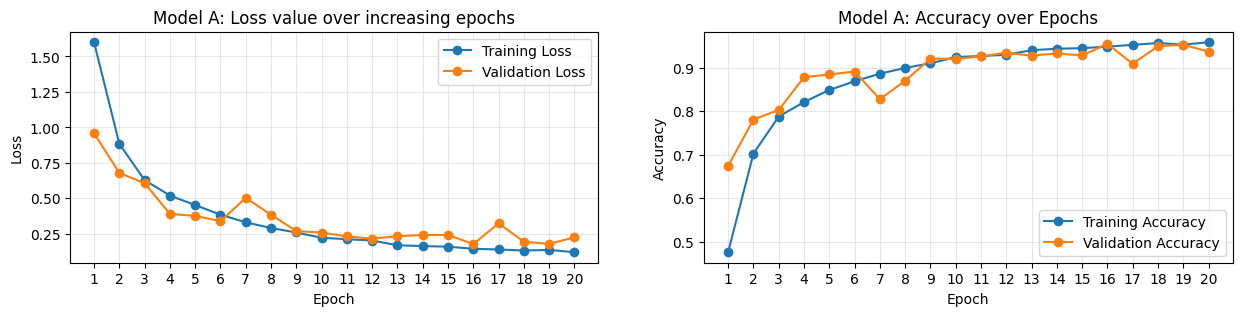

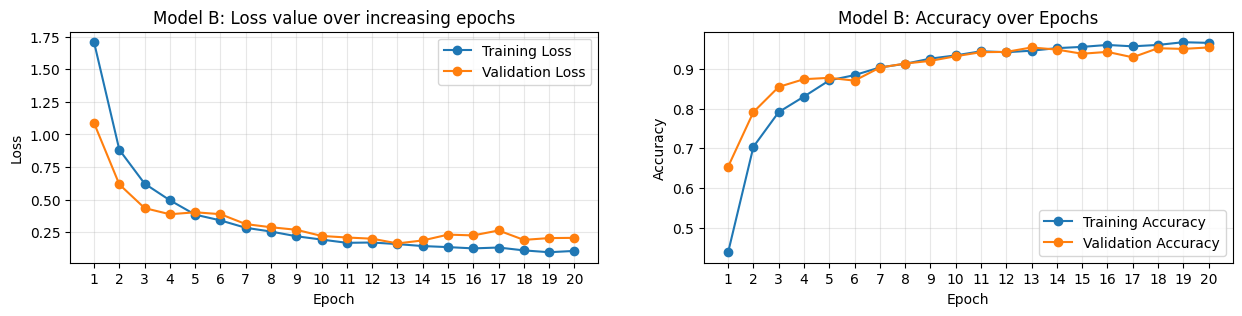

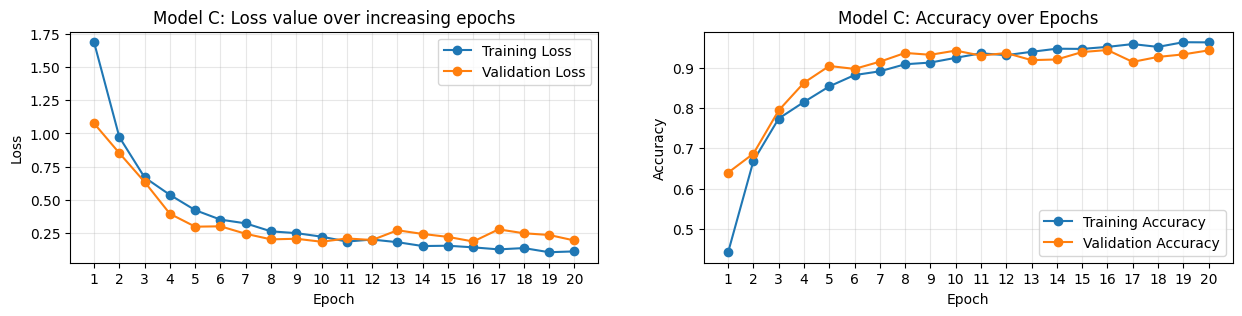

In [19]:
epochs = np.arange(epoch_number) + 1

for choice in ["A", "B", "C"]:
    train_losses, train_accuracies, val_losses, val_accuracies = all_history[choice]

    plt.figure(figsize=(15, 3))
    plt.subplot(121)
    plt.title(f"Model {choice}: Loss value over increasing epochs")
    plt.plot(epochs, train_losses, marker='o', label="Training Loss")
    plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.xticks(epochs)
    plt.legend()
    plt.grid(alpha=0.3)

    plt.subplot(122)
    plt.title(f"Model {choice}: Accuracy over Epochs")
    plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
    plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.xticks(epochs)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

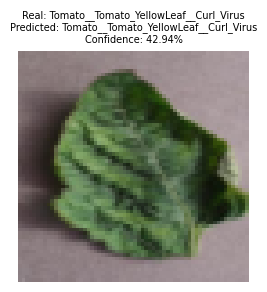

In [20]:
# Predict one test image with the best model
model.eval()
test_img, label = test_data[2]
img = test_img.view(-1, 3, size, size).to(device)

output = model(img)
pred = torch.exp(output) / torch.sum(torch.exp(output))
confidence, index = pred.max(-1)

plt.figure(figsize=(3, 3))
plt.imshow(test_img.view(3, size, size).permute(1, 2, 0))
plt.title(f'Real: {aug_data.classes[label]}\nPredicted: {aug_data.classes[index]}\nConfidence: {confidence.item()*100:0.2f}%', fontsize=7)
plt.axis("off")
plt.show()

## 8. Analysis and Discussion of Results

**1. Best Model**
Model B . The validation accuracy of the three models was:
- Model A (256 -> 15): 93.68%
- Model B (512 -> 256 -> 15): 95.35%
- Model C (256 -> 128 -> 15): 94.38%

Model B has the most Linear layers and neurons, so it could learn more from the features found by the conv layers. Model C had the lowest validation loss (0.1926), but Model B had the best validation accuracy, so we chose Model B.

**2.About overfitting**
There is only a small amount of overfitting. At epoch 20, the gap between training accuracy and validation accuracy was small: Model A 2.15%, Model B 1.15% and Model C 2.00%. After about epoch 12 to 16, the validation loss stopped going down and stayed near 0.2, while the training loss kept going down. This shows that overfitting could start if we trained for more epochs. Model A was also less stable: its validation accuracy fell to 82.75% at epoch 7 and to 90.87% at epoch 17. Models B and C were smoother.

**3. Test accuracy close to the validation accuracy**
The test accuracy of Model B was 93.27% (test loss 0.22), and its validation accuracy was 95.35%. The test accuracy is about 2% lower, but it is still high and close. This means the model works well on new images it has never seen.

**4. Effect of class imbalance**
The classes do not have the same number of images. For example, Tomato Yellow Leaf Curl Virus has 3,208 images, but Potato healthy has only 152 and Tomato mosaic virus has 373. The model sees the big classes more often, so it can learn them better. The overall accuracy can hide a weak result on the small classes. Also, the test set is only 10% of the data, so a small class like Potato healthy has very few test images, and a few mistakes can change its score a lot.

**5. Other observations**
- In the first epochs, the validation accuracy was higher than the training accuracy (for example Model A at epoch 1: 47.58% train and 67.41% validation). This is because the training images are changed on purpose by augmentation, and the training accuracy is counted while the model is still learning during the epoch.
- Images were resized to 64 x 64, so very small leaf spots may be lost.
- In the sample prediction, the model was correct, but its confidence was only 42.94%, so it was not very sure.

## 9. Conclusions and Future Work

**Conclusions:**
- Built a CNN with 2 conv blocks (3-64-64 and 64-128-128) and tried 3 different Linear layer designs.
- The best one was Model B (512 -> 256 -> 15), with a validation accuracy of 95.35% and a test accuracy of 93.27%.
- Adam with learning rate 0.001, batch size 32 and 20 epochs worked well for this dataset.
- The model learned all 15 classes of pepper, potato and tomato leaves, with only a small gap between training and validation accuracy.

**Future work:**
- Use bigger images (for example 128 x 128), so small leaf spots are clearer.
- Use class weights or collect more images for the small classes (like Potato healthy).
- Test the model on real field photos, because PlantVillage images were taken in a lab with a plain background.